In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

wildfire_df = pd.read_csv("../../../data/disaster_data/wildfires/major_wildfires_2000_2026.csv")

# Convert dates
wildfire_df["start_date"] = pd.to_datetime(
    wildfire_df["start_date"],
    errors="coerce"
)

wildfire_df["end_date"] = pd.to_datetime(
    wildfire_df["end_date"],
    errors="coerce"
)

# Convert numeric columns
numeric_cols = [
    "total_damage_usd",
    "total_deaths",
    "total_injuries",
    "duration_days"
]

for col in numeric_cols:
    wildfire_df[col] = pd.to_numeric(
        wildfire_df[col],
        errors="coerce"
    )

# Remove duplicate wildfire IDs
wildfire_df = wildfire_df.drop_duplicates(
    subset=["wildfire_id"]
)

print("Total wildfire records:", len(wildfire_df))
display(wildfire_df.head())


Total wildfire records: 44


,wildfire_id,episode_id,start_date,end_date,state,county,location,total_damage_usd,total_deaths,total_injuries,start_lat,start_lon,event_description,duration_days
0,788675,131864,2018-11-08 06:33:00,2018-11-25 15:00:00,CALIFORNIA,NORTHEAST FOOTHILLS/SACRAMENTO VALLEY,NaN,1.700000e+10,86,12,NaN,NaN,The Camp Fire began on the morning of November...,17.352083
1,1118193,183072,2023-08-08 06:40:00,2023-08-16 00:00:00,HAWAII,MAUI LEEWARD WEST,NaN,5.500000e+09,102,32,NaN,NaN,A wildfire near Lahaina was reported at 6:40 a...,7.722222
2,992562,164114,2021-12-30 11:15:00,2021-12-30 23:00:00,COLORADO,BOULDER & JEFFERSON COUNTIES BELOW 6000 FEET /...,NaN,2.000000e+09,2,6,NaN,NaN,"Marshall Fire devastated portions of Marshall,...",0.489583
3,5144511,1095102,2000-05-04 23:00:00,2000-05-31 23:59:00,NEW MEXICO,LOS ALAMOS,LOS ALAMOS,1.500000e+09,0,0,NaN,NaN,NaN,27.040972
4,774715,129303,2018-07-23 15:00:00,2018-07-31 23:59:00,CALIFORNIA,NORTHERN SACRAMENTO VALLEY,NaN,1.500000e+09,4,0,NaN,NaN,The Carr Fire began on the afternoon of July 2...,8.374306


In [2]:

N = 10

top_wildfires = (
    wildfire_df
    .dropna(subset=["total_damage_usd"])
    .sort_values("total_damage_usd", ascending=False)
    .head(N)
    .copy()
)

top_wildfires["damage_billions"] = (
    top_wildfires["total_damage_usd"] / 1e9
)

display(
    top_wildfires[
        [
            "wildfire_id",
            "start_date",
            "state",
            "damage_billions",
            "duration_days"
        ]
    ]
)


,wildfire_id,start_date,state,damage_billions,duration_days
0,788675,2018-11-08 06:33:00,CALIFORNIA,17.0000,17.352083
1,1118193,2023-08-08 06:40:00,HAWAII,5.5000,7.722222
2,992562,2021-12-30 11:15:00,COLORADO,2.0000,0.489583
3,5144511,2000-05-04 23:00:00,NEW MEXICO,1.5000,27.040972
4,774715,2018-07-23 15:00:00,CALIFORNIA,1.5000,8.374306
5,5335898,2003-10-25 17:37:00,CALIFORNIA,1.0465,6.265278
6,1376918,2026-08-01 10:59:00,WASHINGTON,0.7000,17.250694
7,5335897,2003-10-25 09:00:00,CALIFORNIA,0.6964,6.624306
8,5161401,2000-09-29 00:01:00,CALIFORNIA,0.5470,1.998611
9,38182,2007-06-24 13:00:00,CALIFORNIA,0.5000,6.457639


In [4]:


market_df = pd.read_csv(
    "../../../data/stock_data/market_raw.csv"
)

market_df["Date"] = pd.to_datetime(
    market_df["Date"]
).dt.normalize()

market_df = (
    market_df
    .sort_values("Date")
    .drop_duplicates(subset=["Date"])
    .reset_index(drop=True)
)

sectors = ["SPY", "XLE", "XLU", "XLF", "XLI"]
windows = [1, 5, 14]

# Normalize timestamps to calendar dates
top_wildfires["event_date"] = (
    top_wildfires["start_date"].dt.normalize()
)

top_wildfires = pd.merge_asof(
    top_wildfires.sort_values("event_date"),
    market_df[["Date"]].sort_values("Date"),
    left_on="event_date",
    right_on="Date",
    direction="forward"
)

top_wildfires = top_wildfires.rename(
    columns={"Date": "event_trading_date"}
)

display(
    top_wildfires[
        [
            "wildfire_id",
            "start_date",
            "event_trading_date"
        ]
    ]
)


,wildfire_id,start_date,event_trading_date
0,5144511,2000-05-04 23:00:00,2000-05-04
1,5161401,2000-09-29 00:01:00,2000-09-29
2,5335898,2003-10-25 17:37:00,2003-10-27
3,5335897,2003-10-25 09:00:00,2003-10-27
4,38182,2007-06-24 13:00:00,2007-06-25
5,774715,2018-07-23 15:00:00,2018-07-23
6,788675,2018-11-08 06:33:00,2018-11-08
7,992562,2021-12-30 11:15:00,2021-12-30
8,1118193,2023-08-08 06:40:00,2023-08-08
9,1376918,2026-08-01 10:59:00,NaT


In [5]:

results = []

market_dates = pd.Index(market_df["Date"])

for _, wildfire in top_wildfires.iterrows():

    event_date = wildfire["event_trading_date"]

    if pd.isna(event_date):
        continue

    idx = market_dates.get_loc(event_date)

    for sector in sectors:
        close_col = f"{sector}_Close"

        for window in windows:
            future_idx = idx + window

            if future_idx >= len(market_df):
                continue

            p0 = market_df.loc[idx, close_col]
            p1 = market_df.loc[future_idx, close_col]

            if pd.isna(p0) or pd.isna(p1) or p0 <= 0:
                continue

            pct_return = (p1 / p0 - 1) * 100

            results.append({
                "wildfire_id": wildfire["wildfire_id"],
                "state": wildfire["state"],
                "start_date": wildfire["start_date"],
                "damage_usd": wildfire["total_damage_usd"],
                "sector": sector,
                "window": window,
                "return_pct": pct_return
            })

wildfire_returns = pd.DataFrame(results)

display(wildfire_returns.head(15))


,wildfire_id,state,start_date,damage_usd,sector,window,return_pct
0,5144511,NEW MEXICO,2000-05-04 23:00:00,1.500000e+09,SPY,1,1.212016
1,5144511,NEW MEXICO,2000-05-04 23:00:00,1.500000e+09,SPY,5,-0.374597
2,5144511,NEW MEXICO,2000-05-04 23:00:00,1.500000e+09,SPY,14,-1.101789
3,5144511,NEW MEXICO,2000-05-04 23:00:00,1.500000e+09,XLE,1,1.050428
4,5144511,NEW MEXICO,2000-05-04 23:00:00,1.500000e+09,XLE,5,5.882358
5,5144511,NEW MEXICO,2000-05-04 23:00:00,1.500000e+09,XLE,14,5.724738
6,5144511,NEW MEXICO,2000-05-04 23:00:00,1.500000e+09,XLU,1,0.227312
7,5144511,NEW MEXICO,2000-05-04 23:00:00,1.500000e+09,XLU,5,4.034130
8,5144511,NEW MEXICO,2000-05-04 23:00:00,1.500000e+09,XLU,14,1.761380
9,5144511,NEW MEXICO,2000-05-04 23:00:00,1.500000e+09,XLF,1,0.681202


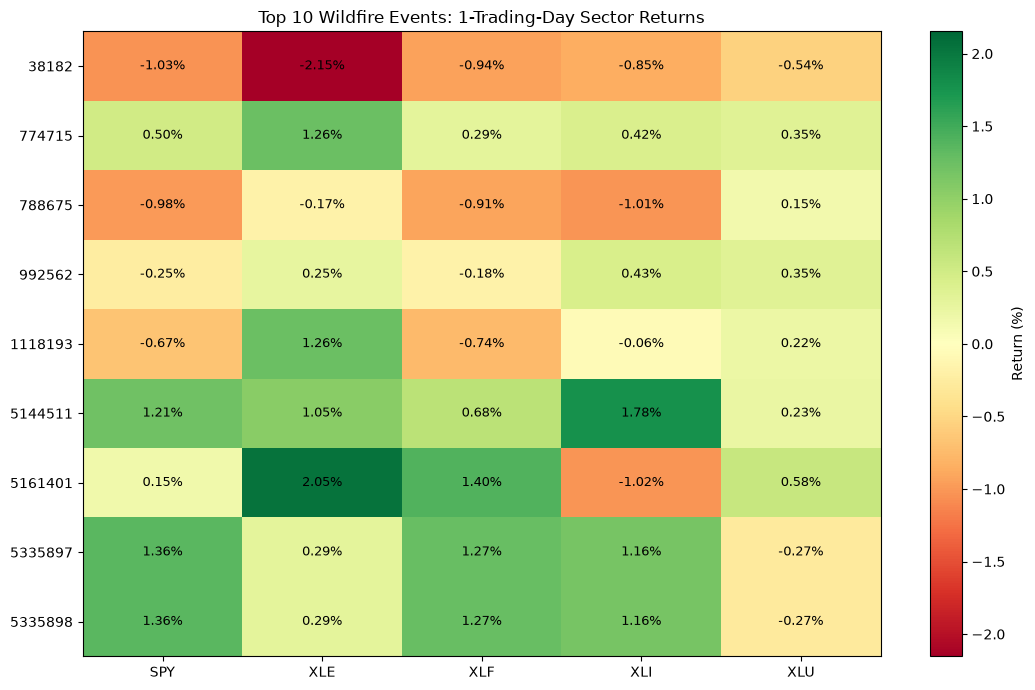

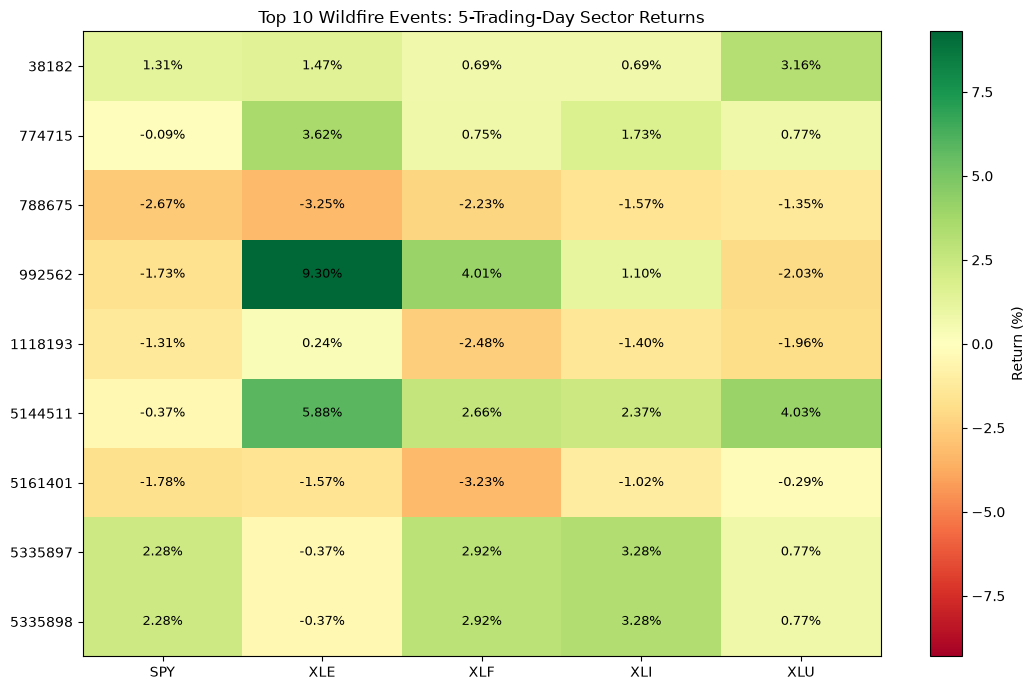

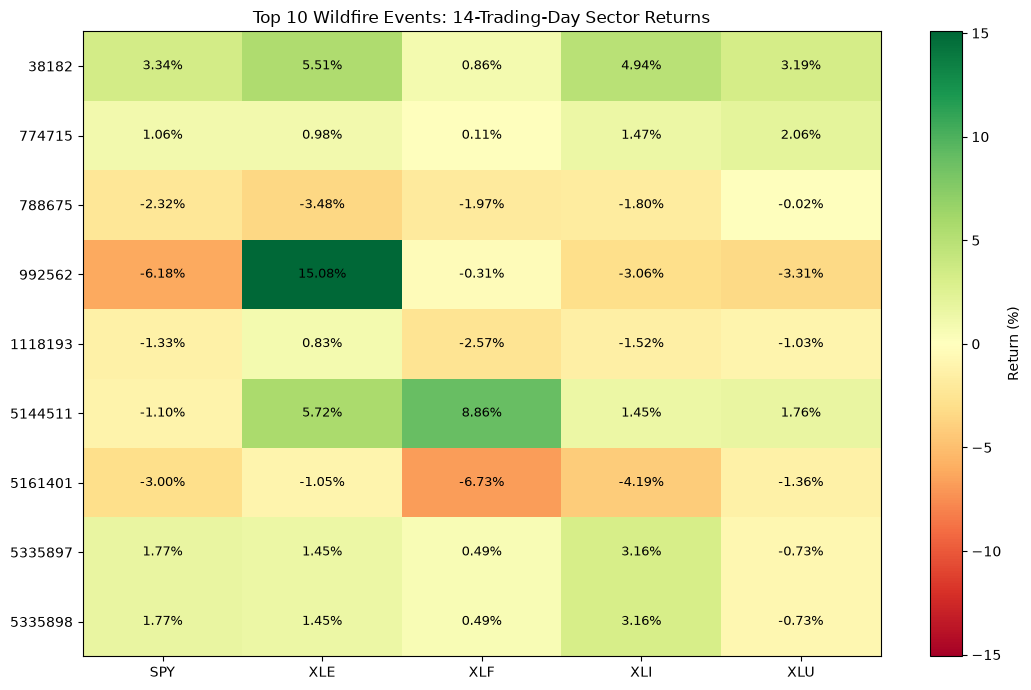

In [6]:

for window in windows:

    heatmap = (
        wildfire_returns[
            wildfire_returns["window"] == window
        ]
        .pivot(
            index="wildfire_id",
            columns="sector",
            values="return_pct"
        )
    )

    fig, ax = plt.subplots(figsize=(11, 7))

    limit = max(
        np.nanmax(np.abs(heatmap.to_numpy())),
        0.01
    )

    im = ax.imshow(
        heatmap,
        cmap="RdYlGn",
        vmin=-limit,
        vmax=limit,
        aspect="auto"
    )

    ax.set_xticks(range(len(heatmap.columns)))
    ax.set_xticklabels(heatmap.columns)

    ax.set_yticks(range(len(heatmap.index)))
    ax.set_yticklabels(heatmap.index)

    for i in range(len(heatmap.index)):
        for j in range(len(heatmap.columns)):

            value = heatmap.iloc[i, j]

            if pd.notna(value):
                ax.text(
                    j, i, f"{value:.2f}%",
                    ha="center",
                    va="center",
                    fontsize=9
                )

    ax.set_title(
        f"Top {N} Wildfire Events: "
        f"{window}-Trading-Day Sector Returns"
    )

    plt.colorbar(
        im,
        ax=ax,
        label="Return (%)"
    )

    plt.tight_layout()
    plt.show()


In [7]:

all_wildfires = wildfire_df.copy()

all_wildfires["event_date"] = (
    all_wildfires["start_date"].dt.normalize()
)

all_wildfires = all_wildfires.dropna(
    subset=["event_date"]
)

all_wildfires = pd.merge_asof(
    all_wildfires.sort_values("event_date"),
    market_df[["Date"]].sort_values("Date"),
    left_on="event_date",
    right_on="Date",
    direction="forward"
)

all_wildfires = all_wildfires.rename(
    columns={"Date": "event_trading_date"}
)

results = []
market_dates = pd.Index(market_df["Date"])

for _, wildfire in all_wildfires.iterrows():

    event_date = wildfire["event_trading_date"]

    if pd.isna(event_date):
        continue

    idx = market_dates.get_loc(event_date)

    for sector in sectors:
        close_col = f"{sector}_Close"

        for window in windows:
            future_idx = idx + window

            if future_idx >= len(market_df):
                continue

            p0 = market_df.loc[idx, close_col]
            p1 = market_df.loc[future_idx, close_col]

            if pd.isna(p0) or pd.isna(p1) or p0 <= 0:
                continue

            results.append({
                "wildfire_id": wildfire["wildfire_id"],
                "sector": sector,
                "window": window,
                "return_pct": (p1 / p0 - 1) * 100
            })

all_wildfire_returns = pd.DataFrame(results)

display(all_wildfire_returns.head())


,wildfire_id,sector,window,return_pct
0,5144511,SPY,1,1.212016
1,5144511,SPY,5,-0.374597
2,5144511,SPY,14,-1.101789
3,5144511,XLE,1,1.050428
4,5144511,XLE,5,5.882358


In [8]:

all_wildfires["high_damage"] = (
    all_wildfires["total_damage_usd"] >= 100_000_000
)

all_wildfires["extreme_damage"] = (
    all_wildfires["total_damage_usd"] >= 1_000_000_000
)

all_wildfires["long_duration"] = (
    all_wildfires["duration_days"] >= 14
)

all_wildfires["very_long_duration"] = (
    all_wildfires["duration_days"] >= 30
)

all_wildfires["fatal_wildfire"] = (
    all_wildfires["total_deaths"] > 0
)

all_wildfires["high_fatalities"] = (
    all_wildfires["total_deaths"] >= 10
)

all_wildfires["high_injuries"] = (
    all_wildfires["total_injuries"] >= 10
)

all_wildfires["california_fire"] = (
    all_wildfires["state"] == "CALIFORNIA"
)


In [9]:

returns_5d = (
    all_wildfire_returns[
        all_wildfire_returns["window"] == 5
    ]
    .pivot(
        index="wildfire_id",
        columns="sector",
        values="return_pct"
    )
)

returns_5d.columns = [
    f"{col}_return_5d"
    for col in returns_5d.columns
]

fp_df = all_wildfires.merge(
    returns_5d,
    on="wildfire_id",
    how="inner"
)

return_cols = [
    f"{sector}_return_5d"
    for sector in sectors
]

fp_df = fp_df.dropna(subset=return_cols)

for sector in sectors:

    fp_df[f"{sector}_up"] = (
        fp_df[f"{sector}_return_5d"] > 0
    )

    fp_df[f"{sector}_down"] = (
        fp_df[f"{sector}_return_5d"] < 0
    )

display(fp_df.head())


,wildfire_id,episode_id,start_date,end_date,state,county,location,total_damage_usd,total_deaths,total_injuries,...,SPY_up,SPY_down,XLE_up,XLE_down,XLU_up,XLU_down,XLF_up,XLF_down,XLI_up,XLI_down
0,5144511,1095102,2000-05-04 23:00:00,2000-05-31 23:59:00,NEW MEXICO,LOS ALAMOS,LOS ALAMOS,1.500000e+09,0,0,...,False,True,True,False,True,False,True,False,True,False
1,5161401,1104076,2000-09-29 00:01:00,2000-09-30 23:59:00,CALIFORNIA,TEHAMA,RED BLUFF,5.470000e+08,0,0,...,False,True,False,True,False,True,False,True,False,True
2,5335898,1163276,2003-10-25 17:37:00,2003-10-31 23:59:00,CALIFORNIA,SAN DIEGO,PINE HILLS,1.046500e+09,14,90,...,True,False,False,True,True,False,True,False,True,False
3,5335897,1163275,2003-10-25 09:00:00,2003-10-31 23:59:00,CALIFORNIA,SAN BERNARDINO,SAN BERNARDINO,6.964000e+08,4,5,...,True,False,False,True,True,False,True,False,True,False
4,5336552,1163928,2003-11-01 00:00:00,2003-11-05 06:00:00,CALIFORNIA,SAN BERNARDINO,HESPERIA,2.786000e+08,2,7,...,False,True,True,False,False,True,False,True,False,True


In [10]:

wildfire_features = [
    "high_damage",
    "extreme_damage",
    "long_duration",
    "very_long_duration",
    "fatal_wildfire",
    "high_fatalities",
    "high_injuries",
    "california_fire"
]

market_features = [
    f"{sector}_{direction}"
    for sector in sectors
    for direction in ["up", "down"]
]

transaction_cols = wildfire_features + market_features

transactions = (
    fp_df[transaction_cols]
    .fillna(False)
    .astype(bool)
)

display(transactions.head())


,high_damage,extreme_damage,long_duration,very_long_duration,fatal_wildfire,high_fatalities,high_injuries,california_fire,SPY_up,SPY_down,XLE_up,XLE_down,XLU_up,XLU_down,XLF_up,XLF_down,XLI_up,XLI_down
0,True,True,True,False,False,False,False,False,False,True,True,False,True,False,True,False,True,False
1,True,False,False,False,False,False,False,True,False,True,False,True,False,True,False,True,False,True
2,True,True,False,False,True,True,True,True,True,False,False,True,True,False,True,False,True,False
3,True,False,False,False,True,False,False,True,True,False,False,True,True,False,True,False,True,False
4,True,False,False,False,True,False,False,True,False,True,True,False,False,True,False,True,False,True


In [11]:

# Install if needed:
# %pip install mlxtend

from mlxtend.frequent_patterns import (
    fpgrowth,
    association_rules
)

frequent_itemsets = fpgrowth(
    transactions,
    min_support=0.15,
    use_colnames=True
)

frequent_itemsets = frequent_itemsets.sort_values(
    "support",
    ascending=False
)

display(frequent_itemsets.head(20))


,support,itemsets
0,0.744186,frozenset({high_damage})
1,0.720930,frozenset({XLU_up})
2,0.674419,frozenset({XLI_up})
3,0.674419,frozenset({XLF_up})
20,0.627907,"frozenset({XLF_up, XLI_up})"
4,0.627907,frozenset({XLE_up})
17,0.604651,"frozenset({XLU_up, XLI_up})"
12,0.604651,frozenset({SPY_up})
21,0.604651,"frozenset({XLF_up, XLU_up})"
196,0.581395,"frozenset({SPY_up, XLF_up})"


In [12]:

rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=0.6
)

rules = rules[
    rules["antecedents"].apply(
        lambda x: (
            len(x) > 0
            and x.issubset(set(wildfire_features))
        )
    )
    &
    rules["consequents"].apply(
        lambda x: (
            len(x) == 1
            and x.issubset(set(market_features))
        )
    )
]

rules = rules[rules["lift"] > 1.2]

rules = rules.sort_values(
    ["lift", "confidence"],
    ascending=False
)

display(
    rules[
        [
            "antecedents",
            "consequents",
            "support",
            "confidence",
            "lift"
        ]
    ].head(20)
)


,antecedents,consequents,support,confidence,lift
1288,"frozenset({high_damage, long_duration})",frozenset({XLF_down}),0.186047,0.615385,1.890110
999,"frozenset({high_damage, long_duration})",frozenset({XLE_down}),0.209302,0.692308,1.860577
753,"frozenset({high_damage, long_duration})",frozenset({SPY_down}),0.209302,0.692308,1.751131
647,frozenset({high_fatalities}),frozenset({SPY_up}),0.209302,0.818182,1.353147
713,"frozenset({high_fatalities, fatal_wildfire})",frozenset({SPY_up}),0.209302,0.818182,1.353147
646,frozenset({high_fatalities}),frozenset({XLF_up}),0.209302,0.818182,1.213166
710,frozenset({high_fatalities}),frozenset({XLI_up}),0.209302,0.818182,1.213166
750,"frozenset({high_fatalities, fatal_wildfire})",frozenset({XLF_up}),0.209302,0.818182,1.213166
1065,"frozenset({high_fatalities, fatal_wildfire})",frozenset({XLI_up}),0.209302,0.818182,1.213166


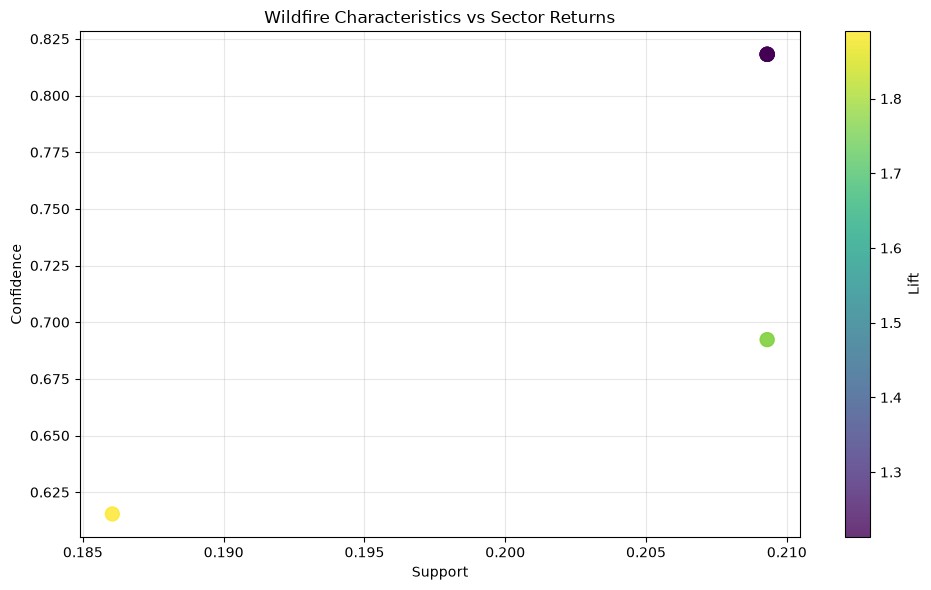

In [13]:

if not rules.empty:

    plt.figure(figsize=(10, 6))

    scatter = plt.scatter(
        rules["support"],
        rules["confidence"],
        c=rules["lift"],
        cmap="viridis",
        s=100,
        alpha=0.8
    )

    plt.colorbar(scatter, label="Lift")

    plt.xlabel("Support")
    plt.ylabel("Confidence")
    plt.title(
        "Wildfire Characteristics vs Sector Returns"
    )

    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

else:
    print("No association rules passed the thresholds.")


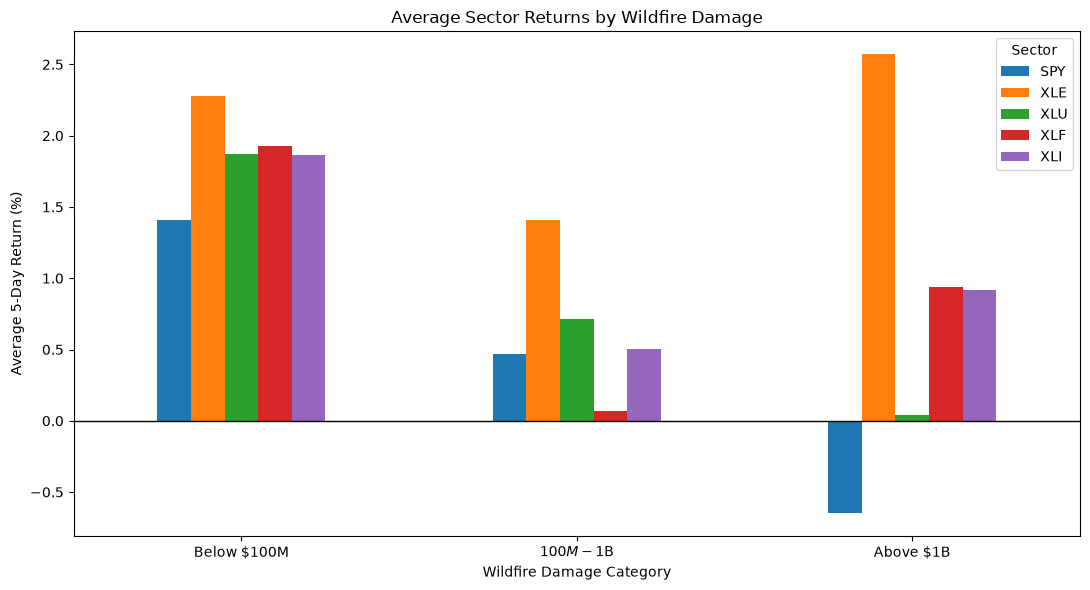

In [14]:

# Group wildfire damage into categories
fp_df["damage_category"] = pd.cut(
    fp_df["total_damage_usd"],
    bins=[
        -np.inf,
        100_000_000,
        1_000_000_000,
        np.inf
    ],
    labels=[
        "Below $100M",
        "$100M-$1B",
        "Above $1B"
    ]
)

# Calculate average returns by damage category
damage_returns = (
    fp_df
    .groupby("damage_category", observed=True)[return_cols]
    .mean()
)

damage_returns.columns = sectors

ax = damage_returns.plot(
    kind="bar",
    figsize=(11, 6)
)

ax.axhline(0, color="black", linewidth=1)

ax.set_xlabel("Wildfire Damage Category")
ax.set_ylabel("Average 5-Day Return (%)")

ax.set_title(
    "Average Sector Returns by Wildfire Damage"
)

plt.xticks(rotation=0)
plt.legend(title="Sector")
plt.tight_layout()
plt.show()
